In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import t

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

np.random.seed(0)

MU_0 = 7
sample_sizes = [50,100,200,400]

# Reproducibility
rng = np.random.default_rng(42)

# --------------------------------------------------
# LOAD POPULATION
# --------------------------------------------------

df = pd.read_csv("27_tch.csv")

population = (
    df["total_tch"]
    .dropna()
    .values
    .astype(float)
)

print("Population size:", len(population))
print("Population mean:", population.mean())
print()

# --------------------------------------------------
# ONE SAMPLE FOR EACH SAMPLE SIZE
# --------------------------------------------------

results = []

for n in sample_sizes:

    # Draw ONE random sample
    sample = rng.choice(
        population,
        size=n,
        replace=True
    )

    # Sample statistics
    sample_mean = np.mean(sample)
    sample_sd = np.std(sample, ddof=1)

    # Standard error
    se = sample_sd / np.sqrt(n)

    # Degrees of freedom
    df_n = n - 1

    # Calculated t-value
    t_value = (sample_mean - MU_0) / se

    # Critical t-values
    t_critical_05 = t.ppf(
        1 - 0.05 / 2,
        df=df_n
    )

    t_critical_01 = t.ppf(
        1 - 0.01 / 2,
        df=df_n
    )

    # Confidence intervals
    ci95_lower = sample_mean - t_critical_05 * se
    ci95_upper = sample_mean + t_critical_05 * se

    ci99_lower = sample_mean - t_critical_01 * se
    ci99_upper = sample_mean + t_critical_01 * se

    # Hypothesis-test decisions
    reject_05 = abs(t_value) > t_critical_05
    reject_01 = abs(t_value) > t_critical_01

    results.append({
        "Sample Size": n,
        "Degrees of Freedom": df_n,
        "Sample Mean": sample_mean,
        "Sample SD": sample_sd,
        "Standard Error": se,
        "t-value": t_value,
        "Critical t (α=0.05)": t_critical_05,
        "Critical t (α=0.01)": t_critical_01,
        "95% CI Lower": ci95_lower,
        "95% CI Upper": ci95_upper,
        "99% CI Lower": ci99_lower,
        "99% CI Upper": ci99_upper,
        "Reject H0 (α=0.05)": reject_05,
        "Reject H0 (α=0.01)": reject_01
    })

# --------------------------------------------------
# RESULTS TABLE
# --------------------------------------------------

results_df = pd.DataFrame(results)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("ONE-SAMPLE t-TEST: EFFECT OF SAMPLE SIZE")
print("=" * 180)
print(results_df.round(4).to_string(index=False))

Population size: 108139
Population mean: 6.93803345693968

ONE-SAMPLE t-TEST: EFFECT OF SAMPLE SIZE
 Sample Size  Degrees of Freedom  Sample Mean  Sample SD  Standard Error  t-value  Critical t (α=0.05)  Critical t (α=0.01)  95% CI Lower  95% CI Upper  99% CI Lower  99% CI Upper  Reject H0 (α=0.05)  Reject H0 (α=0.01)
          50                  49        4.640     4.7370          0.6699  -3.5228               2.0096               2.6800        3.2938        5.9862        2.8447        6.4353                True                True
         100                  99        6.980     9.3192          0.9319  -0.0215               1.9842               2.6264        5.1309        8.8291        4.5324        9.4276               False               False
         150                 149        5.740     5.7957          0.4732  -2.6626               1.9760               2.6092        4.8049        6.6751        4.5053        6.9747                True                True
         200        

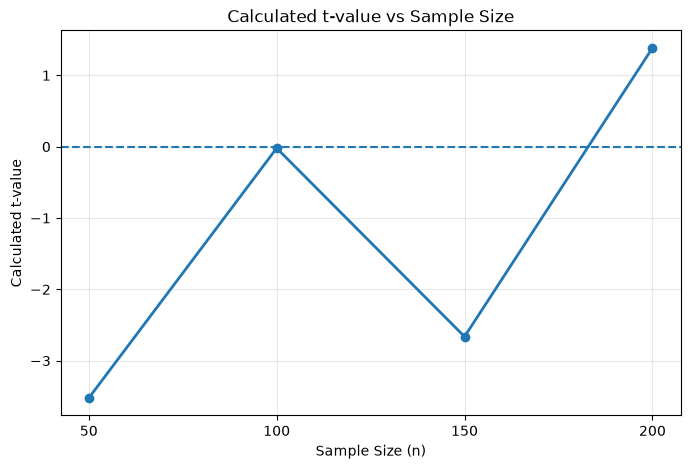

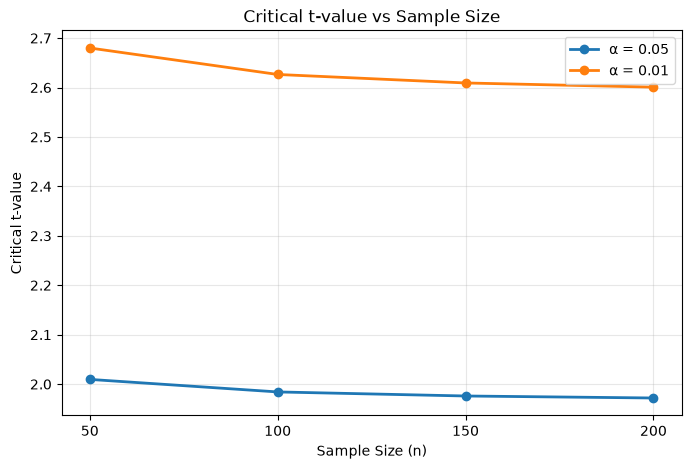

In [81]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# GRAPH 1: CALCULATED t-VALUE
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Sample Size"],
    results_df["t-value"],
    marker="o",
    linewidth=2
)

plt.axhline(0, linestyle="--")

plt.xlabel("Sample Size (n)")
plt.ylabel("Calculated t-value")
plt.title("Calculated t-value vs Sample Size")

plt.xticks(sample_sizes)
plt.grid(alpha=0.3)

plt.show()


# --------------------------------------------------
# GRAPH 2: CRITICAL t-VALUE
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Sample Size"],
    results_df["Critical t (α=0.05)"],
    marker="o",
    linewidth=2,
    label="α = 0.05"
)

plt.plot(
    results_df["Sample Size"],
    results_df["Critical t (α=0.01)"],
    marker="o",
    linewidth=2,
    label="α = 0.01"
)

plt.xlabel("Sample Size (n)")
plt.ylabel("Critical t-value")
plt.title("Critical t-value vs Sample Size")

plt.xticks(sample_sizes)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

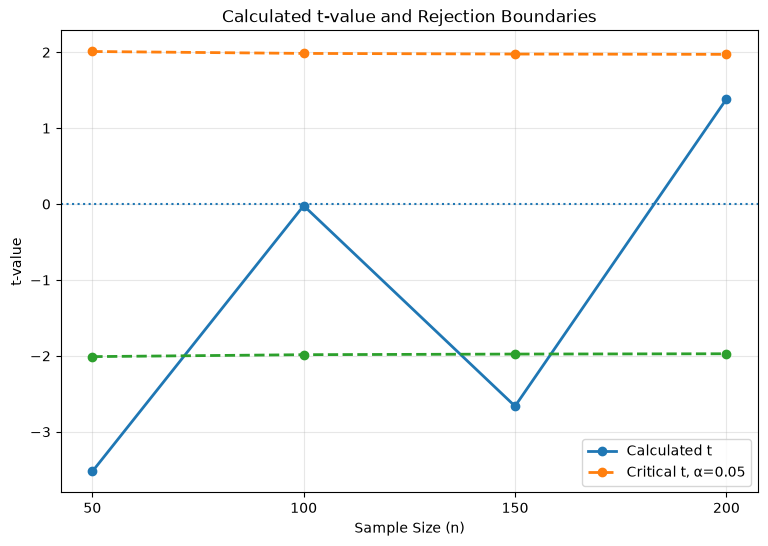

In [82]:
plt.figure(figsize=(9, 6))

plt.plot(
    results_df["Sample Size"],
    results_df["t-value"],
    marker="o",
    linewidth=2,
    label="Calculated t"
)

plt.plot(
    results_df["Sample Size"],
    results_df["Critical t (α=0.05)"],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Critical t, α=0.05"
)

plt.plot(
    results_df["Sample Size"],
    -results_df["Critical t (α=0.05)"],
    marker="o",
    linestyle="--",
    linewidth=2
)

plt.axhline(0, linestyle=":")

plt.xlabel("Sample Size (n)")
plt.ylabel("t-value")
plt.title("Calculated t-value and Rejection Boundaries")

plt.xticks(sample_sizes)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

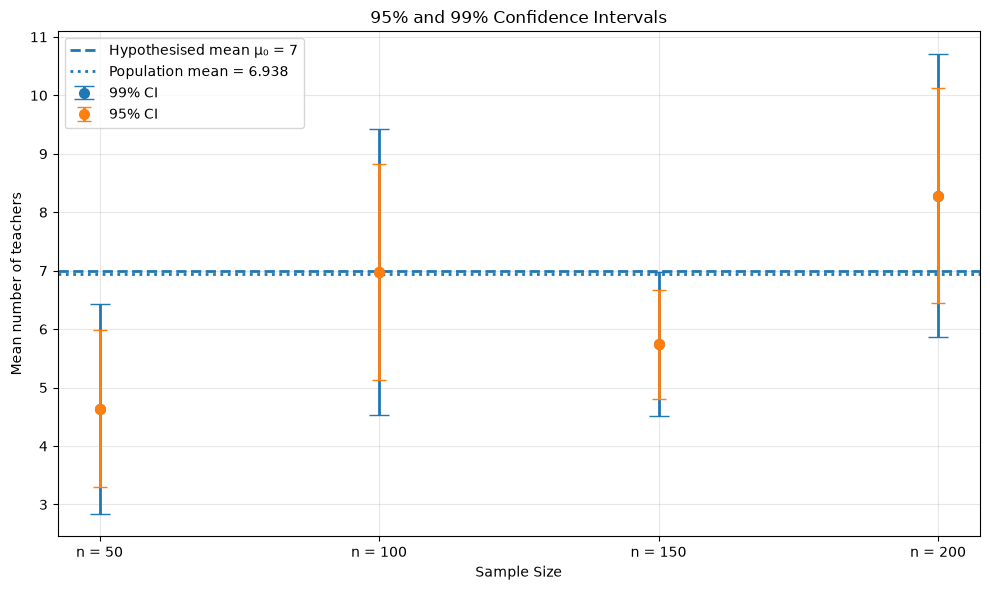

In [83]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# CONFIDENCE INTERVAL PLOT
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(results_df))

means = results_df["Sample Mean"].values

# 95% CI error
ci95_lower_error = means - results_df["95% CI Lower"].values
ci95_upper_error = results_df["95% CI Upper"].values - means

# 99% CI error
ci99_lower_error = means - results_df["99% CI Lower"].values
ci99_upper_error = results_df["99% CI Upper"].values - means

# 99% CI
ax.errorbar(
    x,
    means,
    yerr=[
        ci99_lower_error,
        ci99_upper_error
    ],
    fmt="o",
    capsize=7,
    markersize=7,
    linewidth=2,
    label="99% CI"
)

# 95% CI
ax.errorbar(
    x,
    means,
    yerr=[
        ci95_lower_error,
        ci95_upper_error
    ],
    fmt="o",
    capsize=5,
    markersize=7,
    linewidth=2,
    label="95% CI"
)

# Hypothesised population mean
ax.axhline(
    MU_0,
    linestyle="--",
    linewidth=2,
    label="Hypothesised mean μ₀ = 7"
)

# Empirical population mean
population_mean = population.mean()

ax.axhline(
    population_mean,
    linestyle=":",
    linewidth=2,
    label=f"Population mean = {population_mean:.3f}"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"n = {n}" for n in results_df["Sample Size"]]
)

ax.set_xlabel("Sample Size")
ax.set_ylabel("Mean number of teachers")
ax.set_title("95% and 99% Confidence Intervals")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

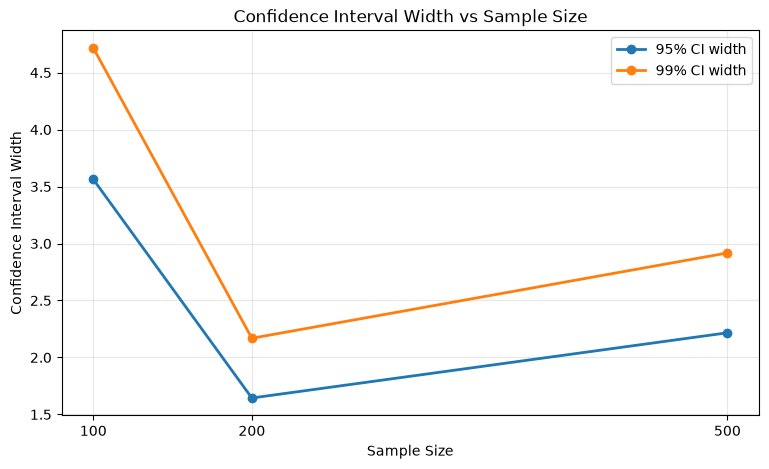

In [77]:
# --------------------------------------------------
# CONFIDENCE INTERVAL WIDTH
# --------------------------------------------------

results_df["95% CI Width"] = (
    results_df["95% CI Upper"]
    - results_df["95% CI Lower"]
)

results_df["99% CI Width"] = (
    results_df["99% CI Upper"]
    - results_df["99% CI Lower"]
)

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Sample Size"],
    results_df["95% CI Width"],
    marker="o",
    linewidth=2,
    label="95% CI width"
)

plt.plot(
    results_df["Sample Size"],
    results_df["99% CI Width"],
    marker="o",
    linewidth=2,
    label="99% CI width"
)

plt.xlabel("Sample Size")
plt.ylabel("Confidence Interval Width")
plt.title("Confidence Interval Width vs Sample Size")

plt.xticks(results_df["Sample Size"])
plt.legend()
plt.grid(alpha=0.3)

plt.show()